<a href="https://colab.research.google.com/github/Sanjanaganguli0306/GenAI-Lab-Experiment/blob/main/Practical%204_GAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting DCGAN Training...

Epoch 01/30 | Generator Loss: 0.8000 | Discriminator Loss: 1.3379 | Discriminator Accuracy: 59.60%
Epoch 02/30 | Generator Loss: 0.8489 | Discriminator Loss: 1.3403 | Discriminator Accuracy: 59.26%
Epoch 03/30 | Generator Loss: 0.9111 | Discriminator Loss: 1.2926 | Discriminator Accuracy: 63.75%
Epoch 04/30 | Generator Loss: 0.9595 | Discriminator Loss: 1.2687 | Discriminator Accuracy: 65.58%
Epoch 05/30 | Generator Loss: 0.9396 | Discriminator Loss: 1.2911 | Discriminator Accuracy: 63.68%
Epoch 06/30 | Generator Loss: 0.9039 | Discriminator Loss: 1.3153 | Discriminator Accuracy: 61.10%
Epoch 07/30 | Generator Loss: 0.9051 | Discriminator Loss: 1.3146 | Discriminator Accuracy: 61.57%
Epoch 08/30 | Generator Loss: 0.8969 | Discriminator Loss: 1.3168 | Discriminator Accuracy: 60.70%
Epoch 09/30 | Generator Loss: 0.9087 | Discriminator Loss: 1.3096 | Discriminator Accuracy: 61.40%
Epoch 10/30 | Generator Loss: 0.9159 | Discriminator Loss: 1.3042 | Discriminator

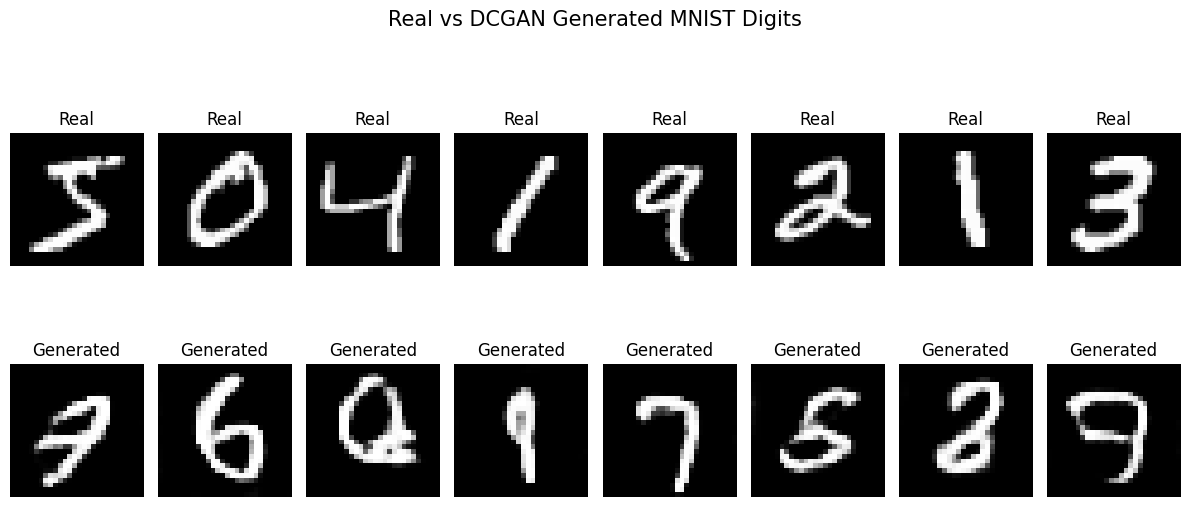


DCGAN Training Completed Successfully!


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. Load MNIST Dataset
(x_train, _), _ = tf.keras.datasets.mnist.load_data()

# 2. Normalize Dataset
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)

# 3. Parameters
BUFFER_SIZE = 60000
BATCH_SIZE = 128
NOISE_DIM = 100
EPOCHS = 30

# 4. Prepare Dataset
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(BUFFER_SIZE).batch(
    BATCH_SIZE, drop_remainder=True
).prefetch(tf.data.AUTOTUNE)

# 5. Build Generator
generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(NOISE_DIM,)),

    tf.keras.layers.Dense(7 * 7 * 256, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(),

    tf.keras.layers.Reshape((7, 7, 256)),

    tf.keras.layers.Conv2DTranspose(
        128, 5, strides=1, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(),

    tf.keras.layers.Conv2DTranspose(
        64, 5, strides=2, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(),

    tf.keras.layers.Conv2DTranspose(
        1, 5, strides=2, padding="same",
        activation="tanh"
    )
])

# 6. Build Discriminator
discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        64, 5, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Conv2D(
        128, 5, strides=2, padding="same"
    ),
    tf.keras.layers.LeakyReLU(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
])

# 7. Loss Function and Optimizers
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

# 8. Training Function
@tf.function
def train_step(real_images):

    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = cross_entropy(
            tf.ones_like(fake_output), fake_output
        )

        real_loss = cross_entropy(
            tf.ones_like(real_output) * 0.9, real_output
        )

        fake_loss = cross_entropy(
            tf.zeros_like(fake_output), fake_output
        )

        d_loss = real_loss + fake_loss

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    # Discriminator accuracy
    real_accuracy = tf.reduce_mean(
        tf.cast(real_output > 0, tf.float32)
    )

    fake_accuracy = tf.reduce_mean(
        tf.cast(fake_output < 0, tf.float32)
    )

    d_accuracy = (real_accuracy + fake_accuracy) / 2

    return g_loss, d_loss, d_accuracy

# 9. Fixed Noise for Image Comparison
seed = tf.random.normal([16, NOISE_DIM])

# 10. Train DCGAN
print("Starting DCGAN Training...\n")

for epoch in range(EPOCHS):

    g_total = 0
    d_total = 0
    acc_total = 0
    batches = 0

    for image_batch in dataset:

        g_loss, d_loss, d_accuracy = train_step(image_batch)

        g_total += float(g_loss)
        d_total += float(d_loss)
        acc_total += float(d_accuracy)
        batches += 1

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Generator Loss: {g_total/batches:.4f} | "
        f"Discriminator Loss: {d_total/batches:.4f} | "
        f"Discriminator Accuracy: {acc_total/batches*100:.2f}%"
    )

# 11. Generate Images
generated_images = generator(seed, training=False)

# 12. Display Real and Generated Images
plt.figure(figsize=(12, 6))

# Real Images
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title("Real")
    plt.axis("off")

# Generated Images
for i in range(8):
    plt.subplot(2, 8, i + 9)
    plt.imshow(
        generated_images[i, :, :, 0] * 0.5 + 0.5,
        cmap="gray"
    )
    plt.title("Generated")
    plt.axis("off")

plt.suptitle("Real vs DCGAN Generated MNIST Digits", fontsize=15)
plt.tight_layout()
plt.show()

print("\nDCGAN Training Completed Successfully!")